# 06 — ML Evaluation & Failure Analysis
**Part D | Milestone 6**

Question: how well do the models predict drift on a sequence they never saw, and where and why do they fail?

Headline numbers are read from files written by `python scripts/evaluate.py` (`results/metrics/<target>.csv`, `<target>_importance.csv`, `results/predictions/<target>.csv`). The failure-analysis tables call `src/vio_drift/evaluation/failure_analysis.py` — the same functions `evaluate.py` uses to write `results/metrics/<target>_failure_*.csv`. Figures come from `src/vio_drift/evaluation/plots.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import joblib
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vio_drift.models.ml.data import load_dataset, load_splits, split_xy, fold_frames
from vio_drift.models.ml.registry import model_specs, MODEL_NAMES

ROOT = Path.cwd().parent
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
sequences = config["data"]["sequences"]
processed = ROOT / config["data"]["processed_dir"]
seed = int(config["seed"])
MODELS_DIR = ROOT / "models" / "ml"
METRICS = ROOT / "results" / "metrics"

TARGET = "err_mag_m"
df = load_dataset(processed, sequences, target=TARGET)
folds = load_splits(processed / "splits.json")

def saved(fold_id, model, target=TARGET):
    """Load a model written by scripts/train_ml.py."""
    return joblib.load(MODELS_DIR / f"{target}__{fold_id}__{model}.joblib")

print(df.shape, "| folds:", [f.fold_id for f in folds])

from vio_drift.evaluation import failure_analysis, plots
from vio_drift.evaluation.metrics import regression_metrics

metrics = pd.read_csv(METRICS / f"{TARGET}.csv")
metrics_bc = pd.read_csv(METRICS / "err_mag_m_bc.csv")
preds = pd.read_csv(ROOT / "results" / "predictions" / f"{TARGET}.csv")
importance = pd.read_csv(METRICS / f"{TARGET}_importance.csv")

def table(m, metric):
    t = m.pivot(index="model", columns="test_seq", values=metric).loc[list(MODEL_NAMES)]
    return t[[*sequences, "all"]].rename(columns={"all": "mean over folds"})

(1843, 108) | folds: ['leave_MH_01_easy', 'leave_MH_02_easy', 'leave_MH_03_medium']


## 1. Final results — `err_mag_m` (primary target)

Held-out MAE (m) per test sequence; the last column is the average over the three folds.

In [2]:
table(metrics, "mae").round(4)

test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0094,0.0101,0.0145,0.0113
linear,0.0088,0.0081,0.0175,0.0115
ridge,0.0077,0.0074,0.0151,0.0100
lasso,0.0076,0.0075,0.0147,0.0099
minibatch_gd,0.0075,0.0075,0.0151,0.0100
random_forest,0.0077,0.0078,0.0151,0.0102


In [3]:
mae_t = table(metrics, "mae")
improvement = (1 - mae_t / mae_t.loc["mean"]) * 100
print("MAE improvement over the mean baseline (%):")
improvement.round(1)

MAE improvement over the mean baseline (%):


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0,0.0,0.0,0.0
linear,6.5,19.9,-21.1,-1.3
ridge,18.4,26.9,-3.9,11.4
lasso,19.7,25.8,-1.7,12.4
minibatch_gd,20.6,25.7,-4.4,11.4
random_forest,18.8,22.3,-3.9,10.2


In [4]:
print("RMSE (m)"); display(table(metrics, "rmse").round(4))
print("R^2"); display(table(metrics, "r2").round(3))

RMSE (m)


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0121,0.0131,0.0210,0.0154
linear,0.0113,0.0106,0.0267,0.0162
ridge,0.0099,0.0094,0.0211,0.0134
lasso,0.0097,0.0096,0.0208,0.0133
minibatch_gd,0.0097,0.0096,0.0211,0.0134
random_forest,0.0099,0.0101,0.0210,0.0136


R^2


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,-0.037,-0.016,-0.047,-0.033
linear,0.103,0.344,-0.701,-0.084
ridge,0.312,0.483,-0.057,0.246
lasso,0.335,0.463,-0.025,0.258
minibatch_gd,0.344,0.463,-0.058,0.250
random_forest,0.312,0.405,-0.049,0.223


**Reading it.** On the two *easy* sequences every model beats the mean baseline; the regularised linear models (Ridge, Lasso, mini-batch GD) and Random Forest do so clearly (MAE down roughly 18–27%, R² ≈ 0.31–0.48), unregularised OLS by much less. On *MH_03_medium* no model beats it: the tuned models are slightly worse or level (Lasso comes closest, 0.0147 vs 0.0145 m), OLS clearly worse (R² ≈ −0.70). Averaged over folds, Lasso (0.0099 m), Ridge and mini-batch GD (0.0100 m) and Random Forest (0.0102 m) are **tied**: differences of 0.0003 m across only three test flights are within noise, so we do not crown a single winner. Inner-CV MAE (notebook 05), which never sees the test flight, tells the same story. The non-linear forest adds nothing measurable over a regularised linear fit here.

## 1b. Over-fitting — training vs held-out error

A model that memorises its training flights has a small error on them and a much larger one on the held-out flight. `evaluate.py` records both: `mae` (held-out) and `train_mae` (the windows the model was fitted on). `ratio = mae / train_mae`.

In [5]:
fit = metrics.assign(ratio=metrics["mae"] / metrics["train_mae"])
display(table(fit, "train_mae").round(4).style.set_caption("train MAE (m)"))
display(table(fit, "mae").round(4).style.set_caption("held-out MAE (m)"))
table(fit, "ratio").round(2).style.set_caption("held-out / train")

test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.012000,0.011300,0.009300,0.010900
linear,0.009400,0.009400,0.006100,0.008300
ridge,0.009700,0.009600,0.006600,0.008600
lasso,0.009900,0.009800,0.006900,0.008900
minibatch_gd,0.009900,0.009800,0.006400,0.008700
random_forest,0.008800,0.009300,0.004500,0.007600


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.009400,0.010100,0.014500,0.011300
linear,0.008800,0.008100,0.017500,0.011500
ridge,0.007700,0.007400,0.015100,0.010000
lasso,0.007600,0.007500,0.014700,0.009900
minibatch_gd,0.007500,0.007500,0.015100,0.010000
random_forest,0.007700,0.007800,0.015100,0.010200


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.790000,0.890000,1.550000,1.040000
linear,0.930000,0.860000,2.860000,1.380000
ridge,0.790000,0.770000,2.300000,1.160000
lasso,0.760000,0.760000,2.140000,1.120000
minibatch_gd,0.760000,0.770000,2.350000,1.150000
random_forest,0.870000,0.840000,3.310000,1.350000


### Before and after Ridge

OLS is Ridge without the penalty. It fits the training flights slightly *better* than Ridge but generalises worse on every fold:

In [6]:
cols = ["mae", "train_mae", "r2"]
before_after = (metrics[metrics["model"].isin(["linear", "ridge"])]
                .pivot(index="test_seq", columns="model", values=cols)
                .loc[[*sequences, "all"]])
before_after[("mae", "change %")] = (before_after[("mae", "ridge")] / before_after[("mae", "linear")] - 1) * 100
before_after.round(4)

mae         train_mae              r2              mae
model         linear   ridge    linear   ridge  linear   ridge change %
test_seq                                                               
MH_01_easy    0.0088  0.0077    0.0094  0.0097  0.1034  0.3123 -12.6989
MH_02_easy    0.0081  0.0074    0.0094  0.0096  0.3443  0.4833  -8.7430
MH_03_medium  0.0175  0.0151    0.0061  0.0066 -0.7007 -0.0565 -14.1916
all           0.0115  0.0100    0.0083  0.0086 -0.0843  0.2463 -12.5314

### What tuning protects against

`scripts/overfit_check.py` refits Ridge, Lasso, mini-batch GD and Random Forest with the **most flexible setting in each grid** (`LOOSE_PARAMS`) and compares it with the tuned model on the same folds.

In [7]:
overfit = pd.read_csv(METRICS / f"{TARGET}_overfit.csv")
o = overfit[overfit["fold_id"] == "mean"]
o.set_index(["model", "setting"])[["train_mae", "test_mae", "ratio"]].round(4)

train_mae  test_mae   ratio
model         setting                             
ridge         tuned       0.0086    0.0100  1.2854
              loose       0.0083    0.0114  1.5450
lasso         tuned       0.0089    0.0099  1.2208
              loose       0.0083    0.0114  1.5439
minibatch_gd  tuned       0.0087    0.0100  1.2923
              loose       0.0084    0.0107  1.4203
random_forest tuned       0.0076    0.0102  1.6747
              loose       0.0028    0.0102  4.0114

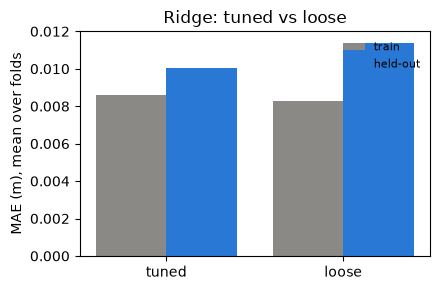

In [8]:
g = o[o["model"] == "ridge"]
x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(x - 0.2, g["train_mae"], 0.4, label="train", color="#8a8985")
ax.bar(x + 0.2, g["test_mae"], 0.4, label="held-out", color="#2a78d6")
ax.set_xticks(x, g["setting"]); ax.set_ylim(0, 0.012)
ax.set_ylabel("MAE (m), mean over folds"); ax.set_title(f"{plots.MODEL_LABELS['ridge']}: tuned vs loose")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

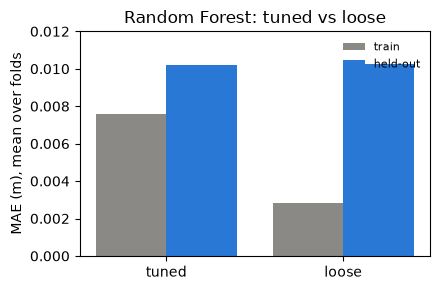

In [9]:
g = o[o["model"] == "random_forest"]
x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(x - 0.2, g["train_mae"], 0.4, label="train", color="#8a8985")
ax.bar(x + 0.2, g["test_mae"], 0.4, label="held-out", color="#2a78d6")
ax.set_xticks(x, g["setting"]); ax.set_ylim(0, 0.012)
ax.set_ylabel("MAE (m), mean over folds"); ax.set_title(f"{plots.MODEL_LABELS['random_forest']}: tuned vs loose")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

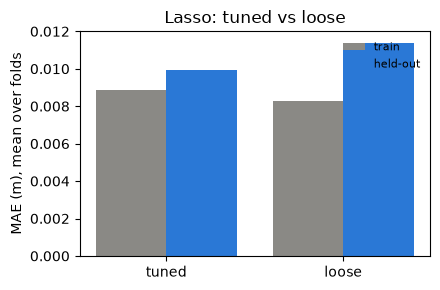

In [10]:
g = o[o["model"] == "lasso"]
x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(x - 0.2, g["train_mae"], 0.4, label="train", color="#8a8985")
ax.bar(x + 0.2, g["test_mae"], 0.4, label="held-out", color="#2a78d6")
ax.set_xticks(x, g["setting"]); ax.set_ylim(0, 0.012)
ax.set_ylabel("MAE (m), mean over folds"); ax.set_title(f"{plots.MODEL_LABELS['lasso']}: tuned vs loose")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

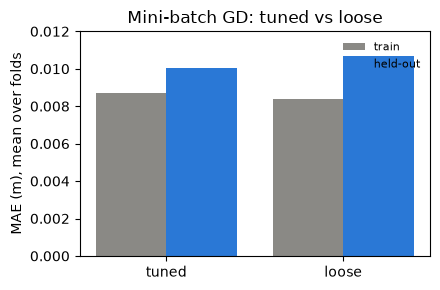

In [11]:
g = o[o["model"] == "minibatch_gd"]
x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(x - 0.2, g["train_mae"], 0.4, label="train", color="#8a8985")
ax.bar(x + 0.2, g["test_mae"], 0.4, label="held-out", color="#2a78d6")
ax.set_xticks(x, g["setting"]); ax.set_ylim(0, 0.012)
ax.set_ylabel("MAE (m), mean over folds"); ax.set_title(f"{plots.MODEL_LABELS['minibatch_gd']}: tuned vs loose")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

**Reading it.**

* **OLS over-fits.** Training MAE 0.0083 m (better than Ridge's 0.0086) but held-out 0.0115 m — worse than the mean baseline (0.0113). Ridge brings held-out MAE to 0.0100 m (−13%) and R² from −0.08 to 0.25.
* **Weaker penalties over-fit; tuning picks the strong ones.** With almost no penalty, Ridge and Lasso both behave like OLS (held-out 0.0114 m vs 0.0100/0.0099 tuned), and mini-batch GD with its weakest penalty does 0.0107 vs 0.0100 m. The deepest Random Forest memorises much harder (training MAE 0.0028 m) but its held-out MAE does not move (0.0102 either way), because averaging 300 decorrelated trees cancels most of what each deep tree memorises. Inner CV rejected every loose setting.
* **The MH_03 gap is distribution shift, not over-fitting.** On the easy folds held-out MAE is *below* training MAE (ratio < 1: those training sets contain the harder MH_03). On MH_03 the ratio jumps to 2.3–3.3 — but the mean baseline, which has nothing to memorise, also jumps to 1.55. Section 3b looks at the shift.

## 2. Figures

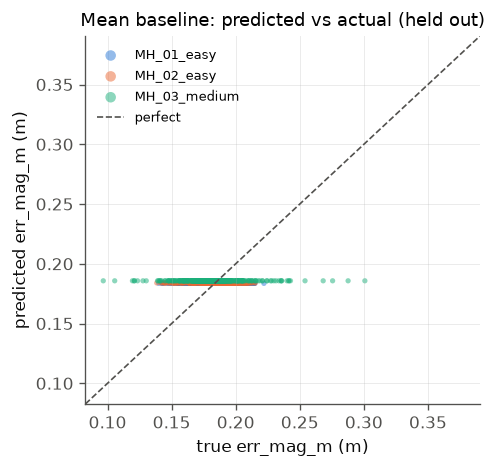

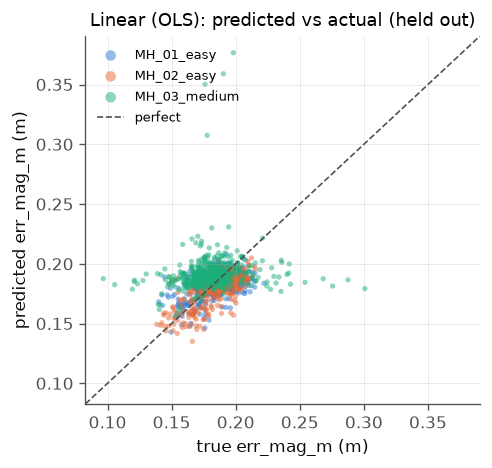

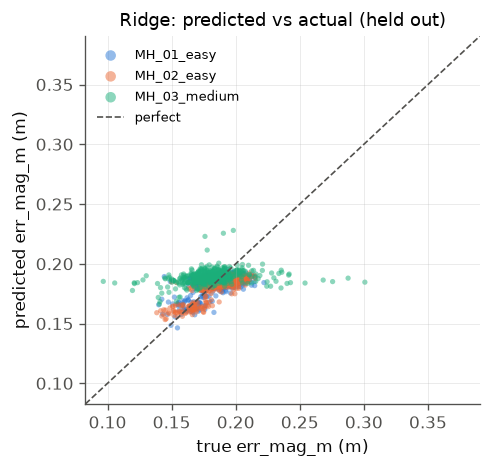

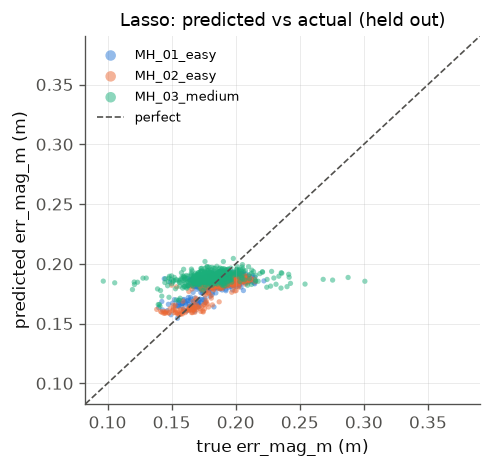

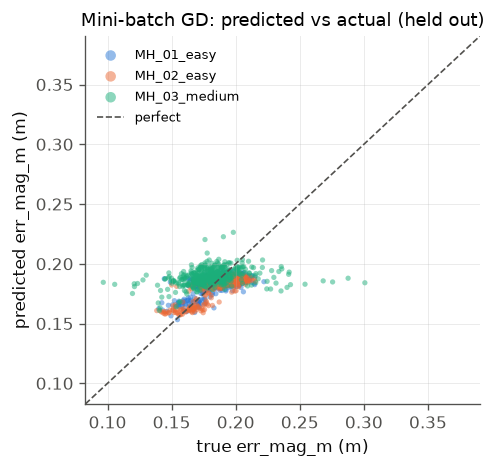

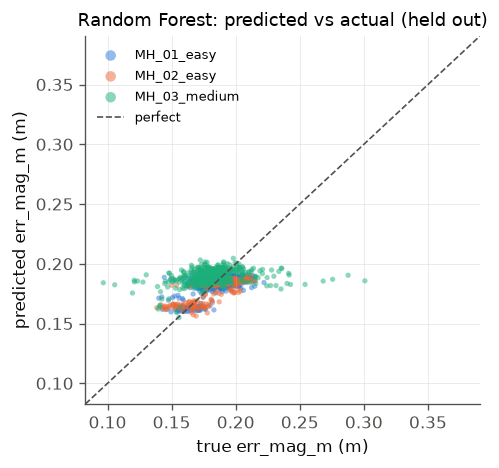

In [12]:
for model in MODEL_NAMES:
    fig = plots.plot_pred_vs_actual(preds, TARGET, model); plt.show()

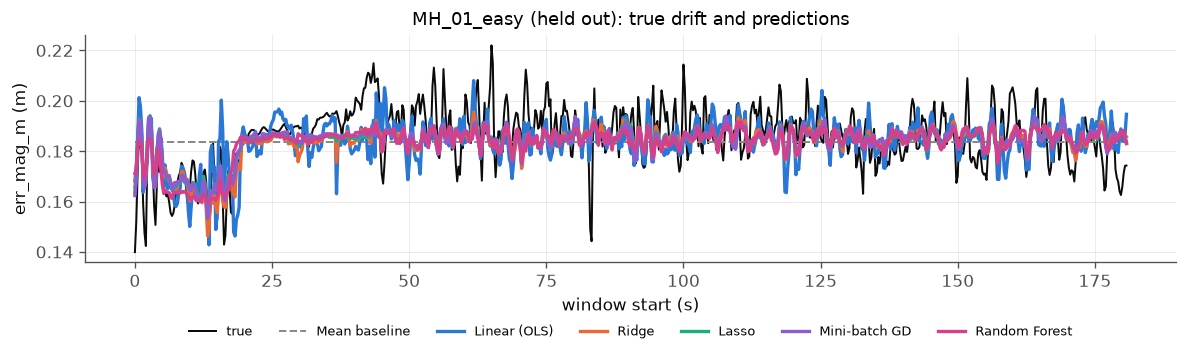

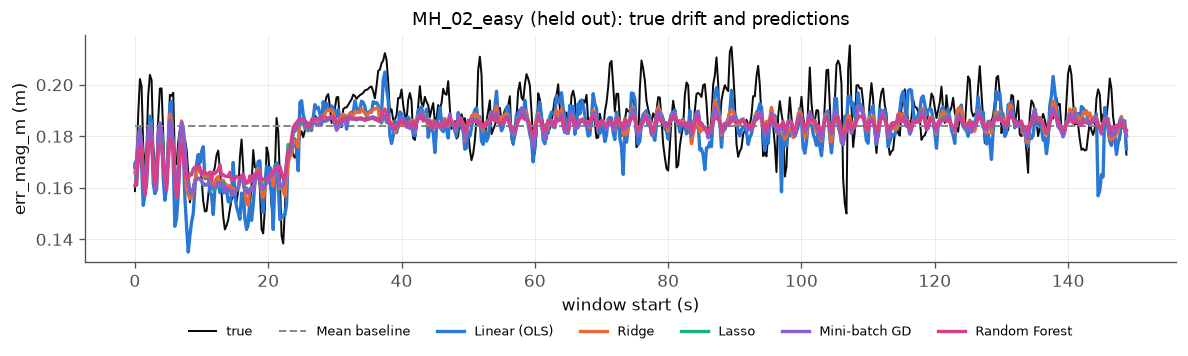

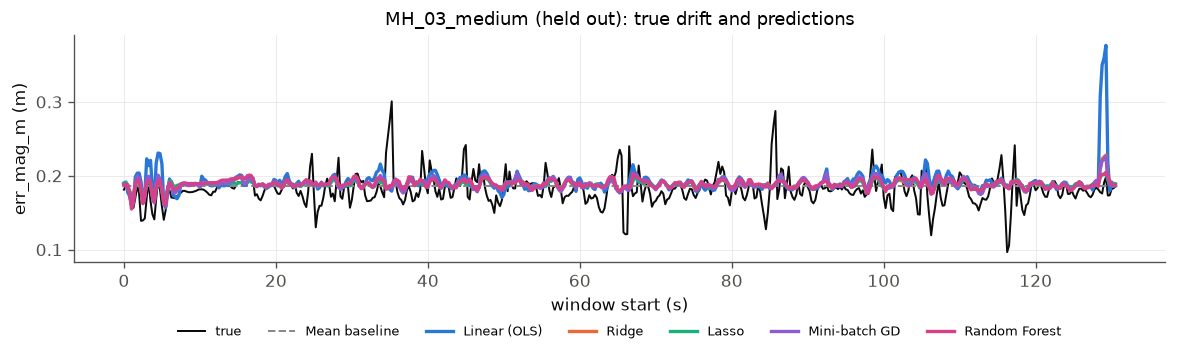

In [13]:
for seq in sequences:
    fig = plots.plot_error_over_time(preds, TARGET, seq); plt.show()

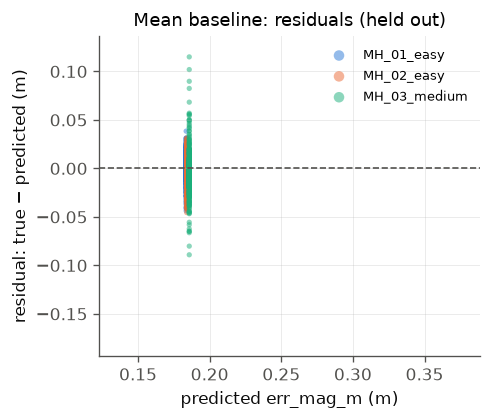

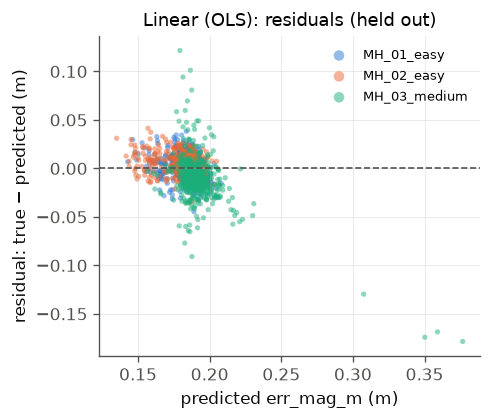

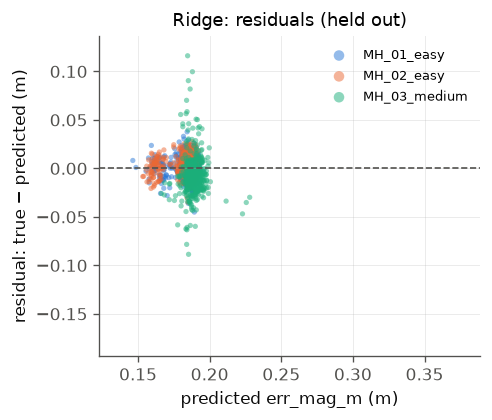

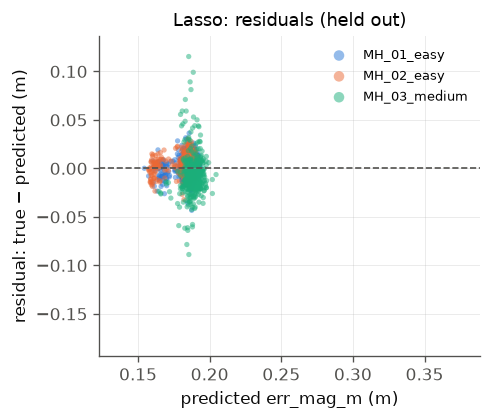

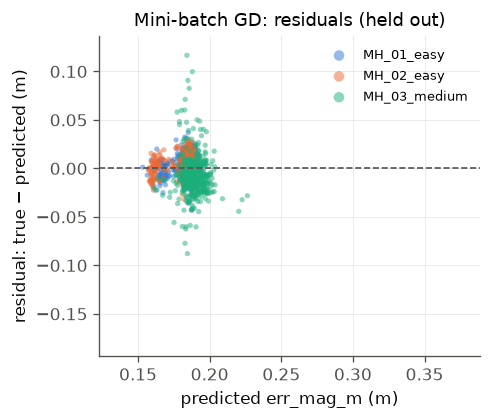

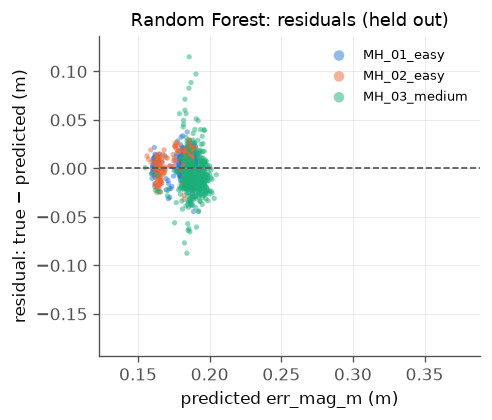

In [14]:
for model in MODEL_NAMES:
    fig = plots.plot_residuals(preds, TARGET, model); plt.show()

## 3. Failure analysis

The aggregate hides two different stories. We look at **where** the error lives (sequence, time, motion level, individual windows) and **why**.

### 3a. Where models win on easy sequences: the opening regime

The time plot shows the first ~20 s of MH_01 and MH_02 sit at a lower drift level (~0.167 m) than the rest (~0.188 m). Splitting the error at that point:

In [15]:
failure_analysis.segment_errors(preds).set_index(["seq_id", "segment"]).round(4)

mean_y_true  mae_lasso  mae_linear  mae_mean  \
seq_id       segment                                                   
MH_01_easy   after_25s       0.1883     0.0078      0.0088    0.0086   
             first_20s       0.1669     0.0072      0.0104    0.0173   
MH_02_easy   after_25s       0.1891     0.0073      0.0075    0.0083   
             first_20s       0.1686     0.0081      0.0114    0.0193   
MH_03_medium after_25s       0.1820     0.0157      0.0185    0.0152   
             first_20s       0.1772     0.0104      0.0134    0.0113   

                        mae_minibatch_gd  mae_random_forest  mae_ridge  
seq_id       segment                                                    
MH_01_easy   after_25s            0.0077             0.0078     0.0079  
             first_20s            0.0072             0.0080     0.0071  
MH_02_easy   after_25s            0.0073             0.0073     0.0072  
             first_20s            0.0081             0.0104     0.0084  
MH_03_medium after_25s            0.0161             0.0160     0.0161  
             first_20s            0.0104             0.0107     0.0102

Most of the gain is in the opening segment: there the features tell the models drift is lower, and they halve the baseline's error. After it, the models improve on the baseline only modestly — they track the general level but not the second-to-second fluctuations.

### 3b. Where models fail: MH_03_medium is out of distribution

When MH_03 is held out, the models train on the two easy flights only. MH_03 moves differently: faster rotation and more jerk, and its label is far more spread out, with spikes up to 0.30 m.

In [16]:
shift = failure_analysis.feature_shift(df, folds, TARGET)
shift.pivot(index="column", columns="test_seq",
            values=["train_mean", "test_mean", "test_std", "test_outside_train_range_pct"]).round(4)

train_mean                          test_mean             \
test_seq      MH_01_easy MH_02_easy MH_03_medium MH_01_easy MH_02_easy   
column                                                                   
ax_mean           9.1010     9.1701       9.0542     9.1178     8.9769   
ax_rms            9.1790     9.2459       9.1179     9.1809     9.0414   
err_mag_m         0.1836     0.1840       0.1858     0.1859     0.1856   
gyro_mag_mean     0.2499     0.2482       0.2127     0.2146     0.2105   
jerk_mag_mean   347.4713   346.4737     325.3462   326.4429   324.0139   

                             test_std                          \
test_seq      MH_03_medium MH_01_easy MH_02_easy MH_03_medium   
column                                                          
ax_mean             9.2423     0.4987     0.7460       0.3472   
ax_rms              9.3359     0.5069     0.7590       0.3601   
err_mag_m           0.1813     0.0119     0.0131       0.0205   
gyro_mag_mean       0.2948     0.1083     0.1052       0.1694   
jerk_mag_mean     374.2028   164.0838   160.6807     129.3771   

              test_outside_train_range_pct                          
test_seq                        MH_01_easy MH_02_easy MH_03_medium  
column                                                              
ax_mean                             0.2762     7.0470       0.0000  
ax_rms                              0.0000     6.8792       0.7648  
err_mag_m                           0.0000     0.0000       5.1625  
gyro_mag_mean                       0.0000     0.0000       4.7801  
jerk_mag_mean                       4.1436     0.0000       0.5736

### 3c. Error broadly grows with rotation rate

Random Forest absolute error by quartile of the window's mean rotation rate (`gyro_mag_mean`), within each held-out sequence. The fastest-rotating quarter of windows has 25–65% more error than the slowest, though not in a steady staircase:

In [17]:
failure_analysis.error_by_quartile(preds, df).set_index("seq_id").round(4)

,mae_Q1,mae_Q2,mae_Q3,mae_Q4,q4_over_q1,model,feature
seq_id,,,,,,,
MH_01_easy,0.0062,0.0074,0.0085,0.0087,1.4091,random_forest,gyro_mag_mean
MH_02_easy,0.0067,0.0071,0.0092,0.0084,1.2514,random_forest,gyro_mag_mean
MH_03_medium,0.0112,0.0161,0.0145,0.0183,1.6306,random_forest,gyro_mag_mean


### 3d. Error is concentrated in label spikes

A tenth of the windows carries roughly 30% of the error. Those are the windows where the true drift jumps away from its usual level, and the models — which predict a smooth level — miss them.

In [18]:
failure_analysis.spike_stats(preds).set_index("seq_id").round(3)

,model,worst10_share,corr_abs_err_vs_label_deviation,corr_pred_true,bias2_share_of_mse
seq_id,,,,,
MH_01_easy,random_forest,0.277,0.649,0.597,0.061
MH_02_easy,random_forest,0.269,0.634,0.699,0.103
MH_03_medium,random_forest,0.320,0.826,0.305,0.135


In [19]:
worst = preds[preds["model"] == "random_forest"].assign(
    abs_err=lambda d: (d["y_true"] - d["y_pred"]).abs())
worst = worst.merge(df[["seq_id", "window_id", "gyro_mag_mean"]], on=["seq_id", "window_id"])
worst.sort_values("abs_err", ascending=False).head(10)[
    ["seq_id", "window_id", "y_true", "y_pred", "abs_err", "gyro_mag_mean"]].round(4)

,seq_id,window_id,y_true,y_pred,abs_err,gyro_mag_mean
1461,MH_03_medium,141,0.3008,0.1857,0.1151,0.1988
1663,MH_03_medium,343,0.2877,0.1904,0.0973,0.1830
1460,MH_03_medium,140,0.2756,0.1870,0.0886,0.2284
1785,MH_03_medium,465,0.0967,0.1841,0.0874,0.1971
1662,MH_03_medium,342,0.2682,0.1855,0.0827,0.1365
1786,MH_03_medium,466,0.1056,0.1824,0.0768,0.2432
1459,MH_03_medium,139,0.2541,0.1827,0.0713,0.3012
1584,MH_03_medium,264,0.1208,0.1862,0.0654,0.5505
1585,MH_03_medium,265,0.1210,0.1849,0.0639,0.6758
1583,MH_03_medium,263,0.1234,0.1856,0.0622,0.4084


**Why.** The prediction/truth correlation drops from 0.60–0.70 on the easy flights to about 0.31 on MH_03, and a constant offset (bias²) explains only 6–14% of the squared error. So the failure is mostly *not* a simple calibration shift that could be fixed by adding a constant: the models cannot see the spikes coming from window-level summary statistics.

### 3e. Which features carry the signal (held-out permutation importance)

Increase in held-out MAE when one feature is shuffled, averaged over folds. Accelerometer level features (`ax_mean`, `ax_rms`, and for Ridge `acc_mag_mean`) dominate both models, matching notebook 04 — consistent with the label being driven largely by how gravity and accelerometer bias project into the integration.

In [20]:
perm = importance[importance["kind"] == "permutation"]
top = (perm.groupby(["model", "feature"])["importance"].mean().mul(1000)
       .rename("MAE increase (mm)").reset_index()
       .sort_values("MAE increase (mm)", ascending=False).groupby("model").head(8))
top.set_index(["model", "feature"]).round(3)

MAE increase (mm)
model         feature                           
ridge         ax_mean                      0.321
              acc_mag_mean                 0.319
              ax_rms                       0.293
random_forest ax_mean                      0.244
              ax_rms                       0.159
ridge         gy_mean                      0.068
              az_spec_entropy              0.058
              ax_skew                      0.057
              ax_spec_entropy              0.052
random_forest az_zcr                       0.052
              az_mean                      0.041
              ay_zcr                       0.035
ridge         gz_skew                      0.033
random_forest az_rms                       0.032
              acc_mag_mean                 0.028
              ay_mean                      0.025

### 3f. Bias-corrected target (oracle comparison)

The same pipeline on `err_mag_m_bc`, the drift left after subtracting the dataset's own bias estimates (`results/metrics/err_mag_m_bc.csv`). R² is near zero (at most 0.05) on every fold and negative on average: once bias is removed, the remaining drift is barely predictable from these motion features.

In [21]:
print("MAE (m)"); display(table(metrics_bc, "mae").round(4))
print("R^2"); display(table(metrics_bc, "r2").round(3))

MAE (m)


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0103,0.0109,0.0154,0.0122
linear,0.0117,0.0116,0.0154,0.0129
ridge,0.0095,0.0102,0.0148,0.0115
lasso,0.0092,0.0102,0.0148,0.0114
minibatch_gd,0.0094,0.0102,0.0148,0.0115
random_forest,0.0092,0.0093,0.0143,0.0109


R^2


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,-0.038,-0.393,-0.186,-0.206
linear,-0.444,-0.807,-0.112,-0.454
ridge,0.023,-0.302,-0.106,-0.128
lasso,0.069,-0.314,-0.116,-0.121
minibatch_gd,0.035,-0.299,-0.117,-0.127
random_forest,0.004,-0.146,-0.082,-0.075


## What we learned

* **Easy sequences: real but modest skill.** Every tuned model beats the mean baseline on MH_01 and MH_02. Most of that comes from recognising the low-drift opening ~20 s; after it the gains are small.
* **MH_03_medium: failure from distribution shift.** Trained only on the easy flights, the models face faster rotation (mean `gyro_mag_mean` about 0.30 vs 0.21 rad/s) and a label with about 1.6× the spread (std 0.0205 vs ~0.0125 m) and spikes to 0.30 m. No model beats the mean there; error broadly grows with rotation rate.
* **Spikes are the residual problem.** About 30% of the error sits in the worst 10% of windows, where the drift jumps. Window summaries do not anticipate them, and the error is not a constant offset that recalibration could remove.
* **Regularisation is what makes the linear model work.** Without a penalty (OLS) it over-fits and loses to the mean baseline; with L2 (Ridge), L1 (Lasso) or a penalised mini-batch GD fit it is the best model. Lasso keeps only 8–11 of the 104 features. Tuning keeps every model's train/held-out gap small; what remains on MH_03 is shift, not memorisation.
* **Model choice matters little.** Lasso, Ridge, mini-batch GD and Random Forest are within ~0.0003 m mean MAE of each other. A regularised linear model is as good as the non-linear forest on this data.
* **Implication for Phase 2.** Better features or models alone are unlikely to fix MH_03; more varied training flights (MH_04/MH_05) and sequence models that see the raw 200×6 signal are the natural next steps.